In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import seaborn as sns

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input, Conv2D, MaxPooling2D,
    Flatten, Dense, Dropout
)

from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import confusion_matrix, classification_report

I0000 00:00:1794637222.554952  108619 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794637222.555146  108619 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1794637222.595580  108619 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1794637224.491633  108619 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:0

In [2]:
train_data = pd.read_csv("sign_mnist_train.csv")
test_data = pd.read_csv("sign_mnist_test.csv")

print("Training Dataset:", train_data.shape)
print("Testing Dataset:", test_data.shape)

train_data.head()

Training Dataset: (27455, 785)
Testing Dataset: (7172, 785)


,label,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,...,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783,pixel784
0,3,107,118,127,134,139,143,146,150,153,...,207,207,207,207,206,206,206,204,203,202
1,6,155,157,156,156,156,157,156,158,158,...,69,149,128,87,94,163,175,103,135,149
2,2,187,188,188,187,187,186,187,188,187,...,202,201,200,199,198,199,198,195,194,195
3,2,211,211,212,212,211,210,211,210,210,...,235,234,233,231,230,226,225,222,229,163
4,13,164,167,170,172,176,179,180,184,185,...,92,105,105,108,133,163,157,163,164,179


In [3]:
X_train = train_data.drop("label", axis=1).values
y_train = train_data["label"].values

X_test = test_data.drop("label", axis=1).values
y_test = test_data["label"].values

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

X_train: (27455, 784)
X_test: (7172, 784)


In [4]:
X_train = X_train / 255.0
X_test = X_test / 255.0

print("Normalization Completed")

Normalization Completed


In [5]:
encoder = LabelEncoder()

y_train = encoder.fit_transform(y_train)
y_test = encoder.transform(y_test)

print("Total Classes:", len(encoder.classes_))
print("Classes:", encoder.classes_)

Total Classes: 24
Classes: [ 0  1  2  3  4  5  6  7  8 10 11 12 13 14 15 16 17 18 19 20 21 22 23 24]


In [6]:
X_train = X_train.reshape(-1, 28, 28, 1)
X_test = X_test.reshape(-1, 28, 28, 1)

print("Training Images:", X_train.shape)
print("Testing Images:", X_test.shape)

Training Images: (27455, 28, 28, 1)
Testing Images: (7172, 28, 28, 1)


In [7]:
model = Sequential([

    Input(shape=(28, 28, 1)),

    Conv2D(32, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),

    Conv2D(64, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),

    Flatten(),

    Dense(128, activation='relu'),

    Dropout(0.3),

    Dense(24, activation='softmax')
])

model.summary()

E0000 00:00:1794637259.230863  108619 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 24)             │         3,096 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 226,840 (886.09 KB)

 Trainable params: 226,840 (886.09 KB)

 Non-trainable params: 0 (0.00 B)

In [8]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

print("CNN Model Compiled Successfully")

CNN Model Compiled Successfully


In [9]:
history = model.fit(
    X_train,
    y_train,
    epochs=15,
    batch_size=128,
    validation_split=0.2
)

Epoch 1/15
172/172 ━━━━━━━━━━━━━━━━━━━━ 3s 16ms/step - accuracy: 0.3960 - loss: 2.0363 - val_accuracy: 0.8039 - val_loss: 0.7761
Epoch 2/15
172/172 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - accuracy: 0.7877 - loss: 0.6653 - val_accuracy: 0.9557 - val_loss: 0.2391
Epoch 3/15
172/172 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - accuracy: 0.9021 - loss: 0.3161 - val_accuracy: 0.9905 - val_loss: 0.0873
Epoch 4/15
172/172 ━━━━━━━━━━━━━━━━━━━━ 3s 20ms/step - accuracy: 0.9497 - loss: 0.1689 - val_accuracy: 0.9976 - val_loss: 0.0433
Epoch 5/15
172/172 ━━━━━━━━━━━━━━━━━━━━ 3s 20ms/step - accuracy: 0.9716 - loss: 0.1033 - val_accuracy: 0.9991 - val_loss: 0.0221
Epoch 6/15
172/172 ━━━━━━━━━━━━━━━━━━━━ 3s 16ms/step - accuracy: 0.9824 - loss: 0.0686 - val_accuracy: 0.9998 - val_loss: 0.0096
Epoch 7/15
172/172 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - accuracy: 0.9854 - loss: 0.0524 - val_accuracy: 0.9998 - val_loss: 0.0061
Epoch 8/15
172/172 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - accuracy: 0.9884 - loss: 0.0428 - val_accu

In [10]:
test_loss, test_accuracy = model.evaluate(
    X_test,
    y_test,
    verbose=0
)

print("Testing Loss:", test_loss)
print("Testing Accuracy:", test_accuracy * 100, "%")

Testing Loss: 0.2718423306941986
Testing Accuracy: 92.83323884010315 %


In [11]:
train_loss, train_accuracy = model.evaluate(
    X_train,
    y_train,
    verbose=0
)

print("Training Accuracy:", train_accuracy * 100, "%")

Training Accuracy: 100.0 %


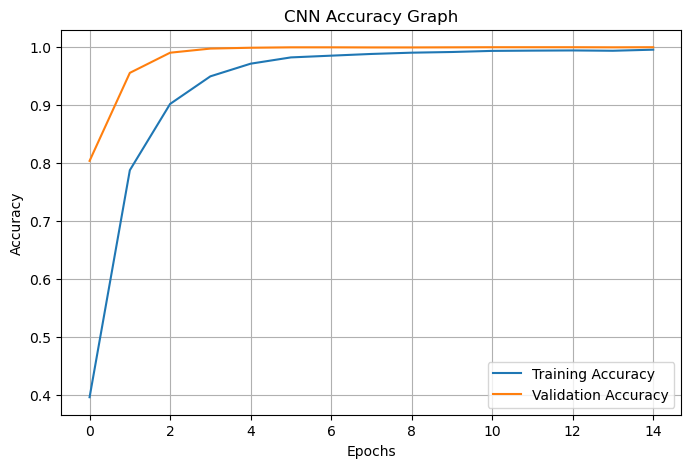

In [12]:
plt.figure(figsize=(8, 5))

plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.title("CNN Accuracy Graph")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")

plt.legend()
plt.grid()
plt.show()

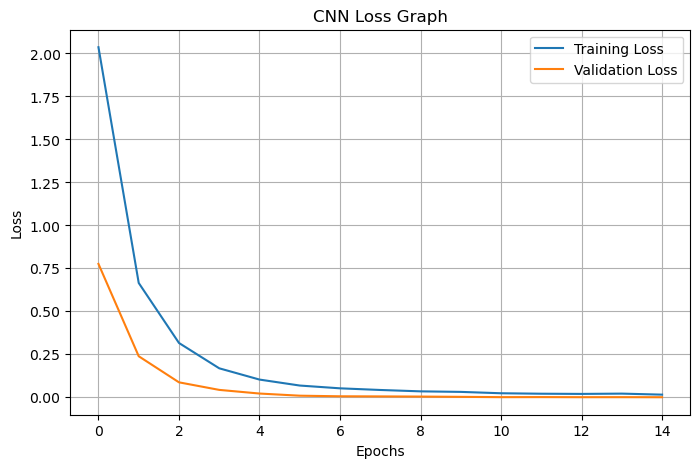

In [13]:
plt.figure(figsize=(8, 5))

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.title("CNN Loss Graph")
plt.xlabel("Epochs")
plt.ylabel("Loss")

plt.legend()
plt.grid()
plt.show()

In [14]:
predictions = model.predict(X_test[:5])

predicted_labels = np.argmax(predictions, axis=1)

actual_letters = encoder.inverse_transform(y_test[:5])
predicted_letters = encoder.inverse_transform(predicted_labels)

for i in range(5):

    print("Actual Letter:", actual_letters[i])
    print("Predicted Letter:", predicted_letters[i])
    print("--------------------------")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step
Actual Letter: 6
Predicted Letter: 6
--------------------------
Actual Letter: 5
Predicted Letter: 5
--------------------------
Actual Letter: 10
Predicted Letter: 10
--------------------------
Actual Letter: 0
Predicted Letter: 0
--------------------------
Actual Letter: 3
Predicted Letter: 3
--------------------------


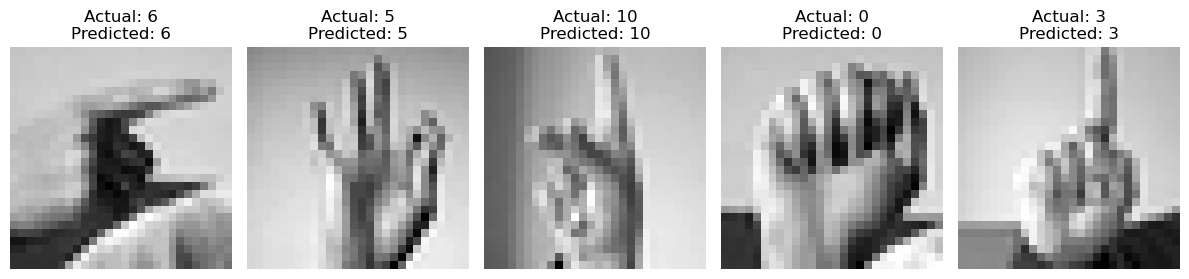

In [15]:
plt.figure(figsize=(12, 5))

for i in range(5):

    plt.subplot(1, 5, i + 1)

    plt.imshow(X_test[i].reshape(28, 28), cmap='gray')

    plt.title(
        f"Actual: {actual_letters[i]}\nPredicted: {predicted_letters[i]}"
    )

    plt.axis('off')

plt.tight_layout()
plt.show()

In [17]:
# First call the model to build it
_ = model(X_test[:1])

# Create feature extraction model
feature_extractor = tf.keras.Model(
    inputs=model.inputs,
    outputs=model.get_layer('flatten').output
)

# Extract features
features = feature_extractor.predict(X_test[:10])

print("Extracted Features Shape:", features.shape)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step
Extracted Features Shape: (10, 1600)


In [18]:
y_pred = model.predict(X_test)

y_pred_labels = np.argmax(y_pred, axis=1)

print(classification_report(
    y_test,
    y_pred_labels,
    target_names=[str(x) for x in encoder.classes_]
))

225/225 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
              precision    recall  f1-score   support

           0       0.89      1.00      0.94       331
           1       1.00      0.95      0.98       432
           2       0.99      1.00      1.00       310
           3       0.92      0.95      0.93       245
           4       0.96      0.99      0.98       498
           5       0.99      1.00      0.99       247
           6       0.89      0.84      0.86       348
           7       1.00      0.95      0.98       436
           8       0.93      0.87      0.90       288
          10       0.99      0.88      0.93       331
          11       0.91      1.00      0.95       209
          12       0.90      0.94      0.92       394
          13       1.00      0.63      0.77       291
          14       1.00      0.98      0.99       246
          15       0.95      1.00      0.97       347
          16       0.89      1.00      0.94       164
          17       0.99      0.85      0